
📊 Density = 3


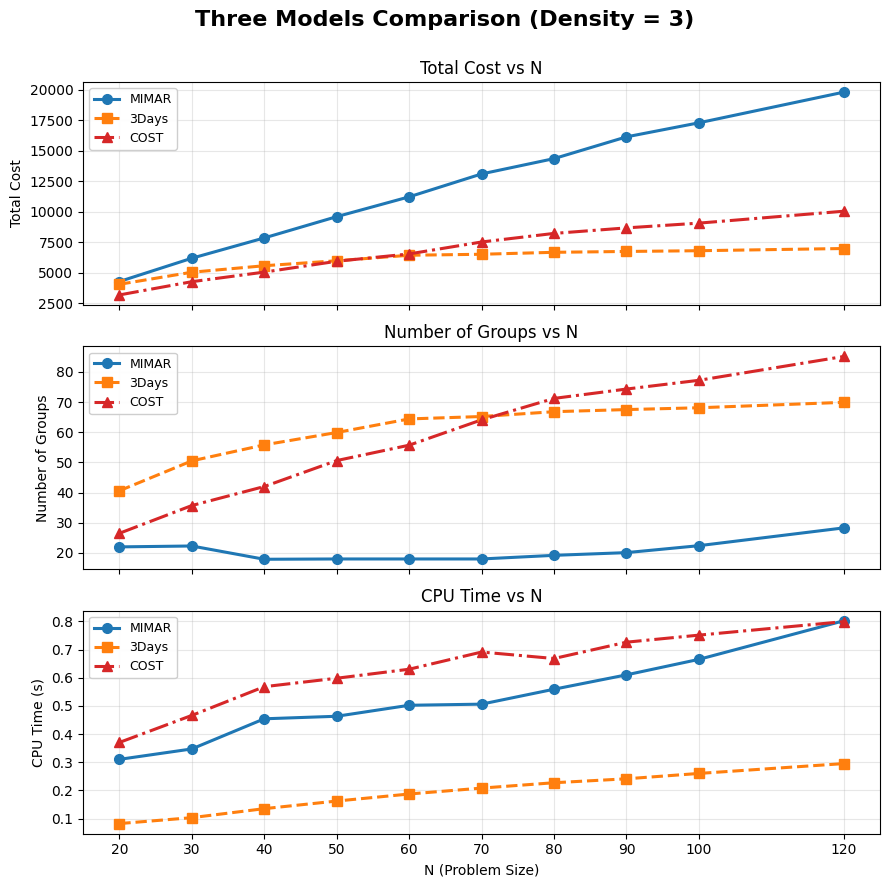

  ✅ Saved: three_models_density_3.png

📊 Density = 6


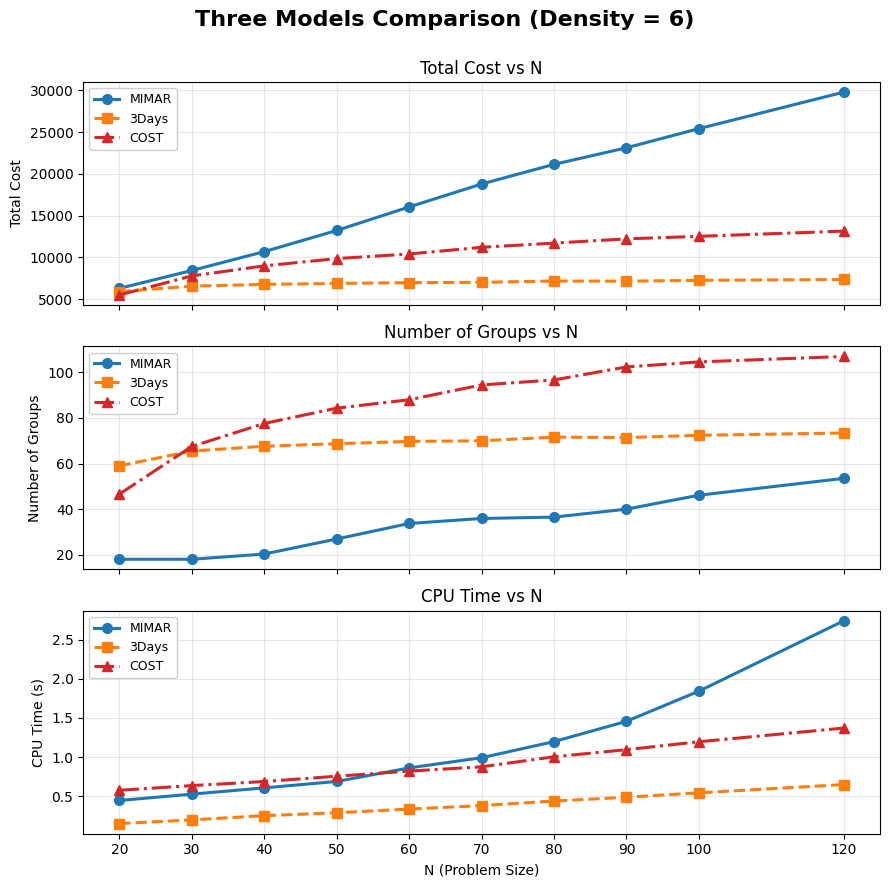

  ✅ Saved: three_models_density_6.png

📊 Density = 13


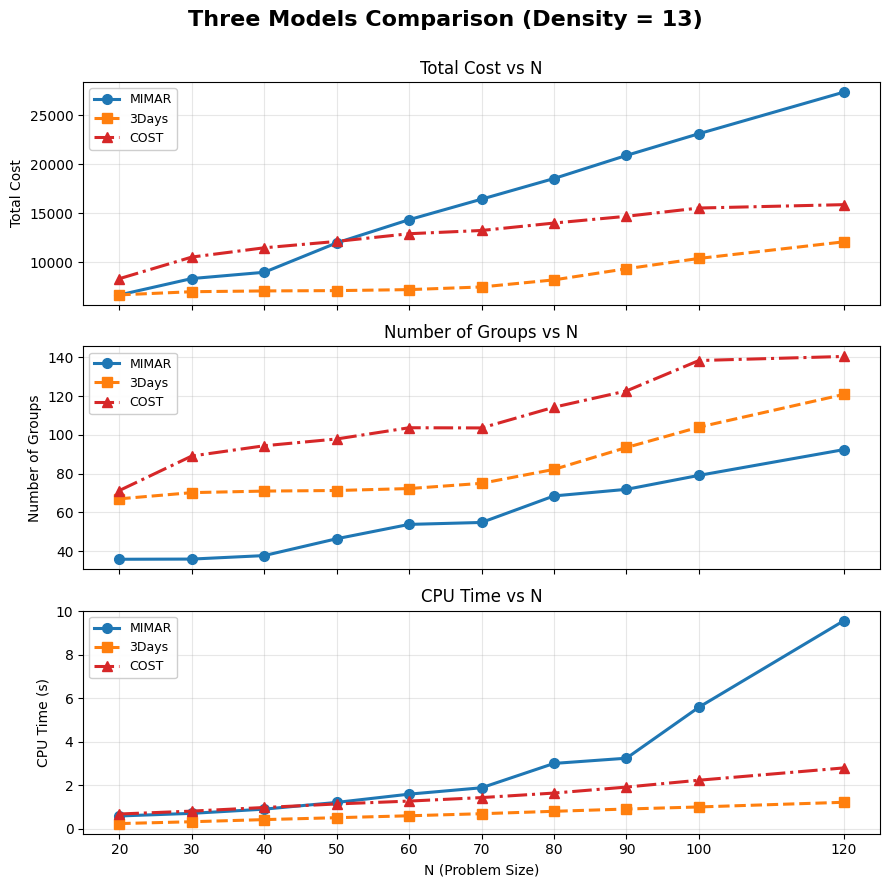

  ✅ Saved: three_models_density_13.png


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import glob
import os

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 300


def plot_per_density_all_models(
    model_dirs,
    model_names,
    task_densities,
    output_prefix="three_models"
):
    """
    对于每一个任务密度 density，画一张包含三个模型的对比图（3 行子图）：
    - Total_cost vs N
    - nb_groups vs N
    - total_clustering_cpu_s vs N

    model_dirs: 例如 ['N_sensitivity_MIMAR_results_2026',
                     'N_sensitivity_3Days_results_2026',
                     'N_sensitivity_COST_results_2026']
    model_names: ['MIMAR', '3Days', 'COST']
    task_densities: 例如 [1, 10, 20, 50, 100]
    """

    colors = ['#1f77b4', '#ff7f0e', '#d62728']
    markers = ['o', 's', '^']
    linestyles = ['-', '--', '-.']

    # 先从任意一个目录读出全局 N 集合（假设三个模型用的 N 集合相同，或重合度很高）
    all_N = set()
    for d in model_dirs:
        grand_file = os.path.join(d, "GRAND_SUMMARY_all_densities_all_N.csv")
        if os.path.exists(grand_file):
            tmp = pd.read_csv(grand_file)
            all_N.update(tmp["N"].unique())
    N_all_sorted = sorted(all_N)

    metrics = [
        ("Total_cost", "Total Cost", "Total Cost vs N"),
        ("nb_groups", "Number of Groups", "Number of Groups vs N"),
        ("total_clustering_cpu_s", "CPU Time (s)", "CPU Time vs N"),
    ]

    for density in task_densities:
        print(f"\n📊 Density = {density}")

        fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
        fig.suptitle(f"Three Models Comparison (Density = {density})",
                     fontsize=16, fontweight="bold")

        # 每个模型一条线
        for m_idx, (model_dir, model_name) in enumerate(zip(model_dirs, model_names)):
            color = colors[m_idx]
            marker = markers[m_idx]
            linestyle = linestyles[m_idx]

            # 优先用 SUMMARY_density_x_all_N.csv，如果没有就从 GRAND 中筛 density
            summary_file = os.path.join(model_dir,
                                        f"SUMMARY_density_{density}_all_N.csv")
            if os.path.exists(summary_file):
                df = pd.read_csv(summary_file)
            else:
                grand_file = os.path.join(model_dir,
                                          "GRAND_SUMMARY_all_densities_all_N.csv")
                if not os.path.exists(grand_file):
                    print(f"  ⚠️  {model_name}: no data file for density {density}")
                    continue
                df_all = pd.read_csv(grand_file)
                df = df_all[df_all["target_daily_tasks"] == density]
                if df.empty:
                    print(f"  ⚠️  {model_name}: no rows for density {density}")
                    continue

            # 每个 N 聚合多 seed
            agg = df.groupby("N").agg({
                "Total_cost": "mean",
                "nb_groups": "mean",
                "total_clustering_cpu_s": "mean"
            }).round(3)

            # 只保留有数据的 N
            N_model = sorted(agg.index.tolist())

            for ax, (col, ylabel, title) in zip(axes, metrics):
                y = agg.loc[N_model, col].values
                ax.plot(
                    N_model, y,
                    marker=marker,
                    linestyle=linestyle,
                    color=color,
                    linewidth=2.2,
                    markersize=7,
                    label=model_name
                )
                ax.set_ylabel(ylabel)
                ax.grid(True, alpha=0.3)
                ax.set_title(title)

        # 统一图例、X 轴设置
        axes[-1].set_xlabel("N (Problem Size)")
        axes[-1].set_xticks(N_all_sorted)
        for ax in axes:
            ax.legend(loc="upper left", framealpha=0.95, fontsize=9)

        plt.tight_layout()
        plt.subplots_adjust(top=0.90)

        out_name = f"{output_prefix}_density_{density}.png"
        plt.savefig(out_name, dpi=300, bbox_inches="tight")
        plt.show()
        print(f"  ✅ Saved: {out_name}")


if __name__ == "__main__":
    # 三个模型结果目录（按你的实际命名改）
    model_dirs = [
        "N_sensitivity_MIMAR_results_2026",
        "N_sensitivity_3Days_results_2026",      # 或 N_sensitivity_Simple_results_2026
        "N_sensitivity_COST_results_2026"
    ]
    model_names = ["MIMAR", "3Days", "COST"]

    # 你希望对比的任务密度（要和实验时保持一致）
    densities = [3, 6, 13]

    plot_per_density_all_models(model_dirs, model_names, densities,
                                output_prefix="three_models")



📊 Density = 1


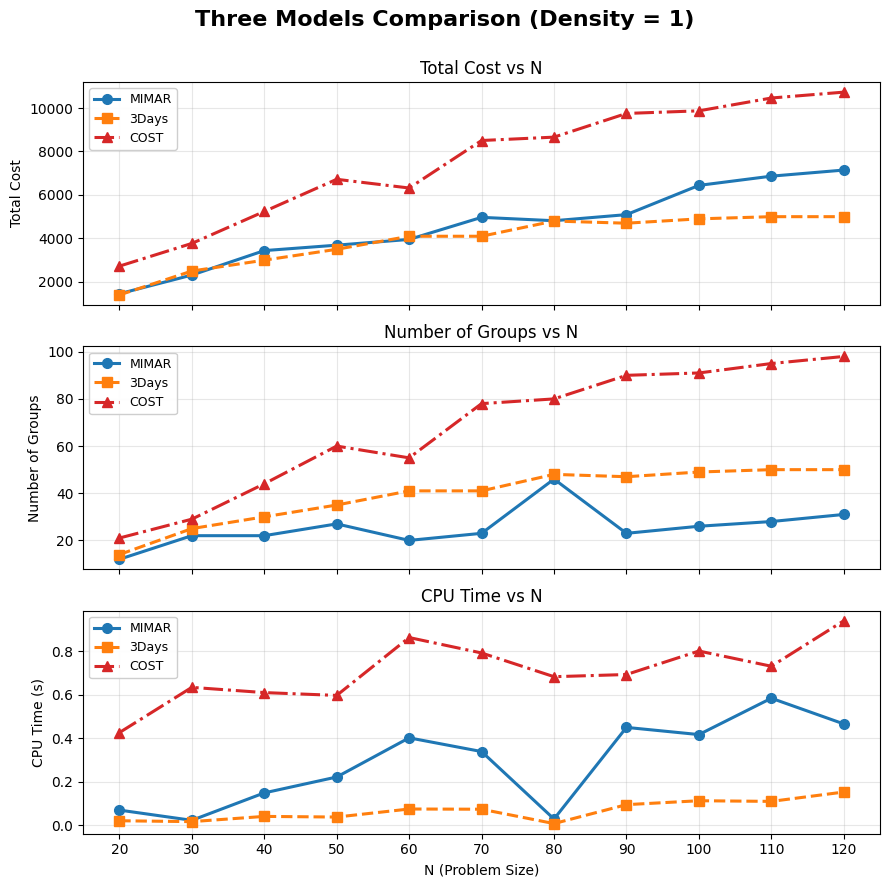

  ✅ Saved: three_models_density_1.png

📊 Density = 12


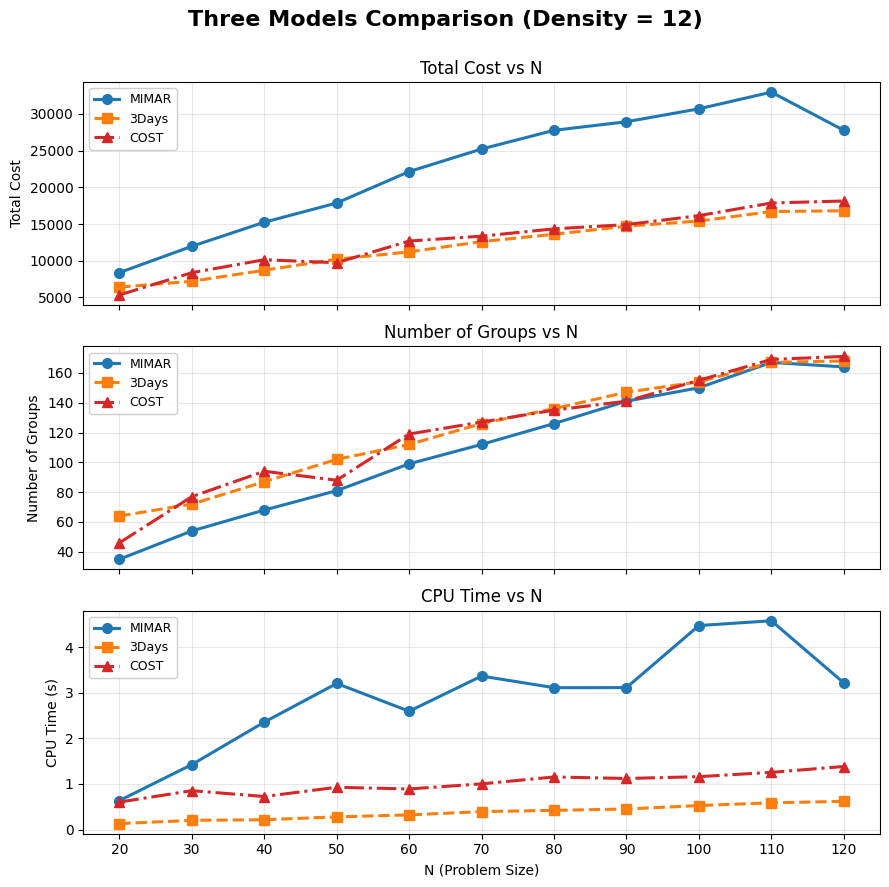

  ✅ Saved: three_models_density_12.png


In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import glob
import os

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 300


def plot_per_density_all_models(
    model_dirs,
    model_names,
    task_densities,
    output_prefix="three_models"
):
    """
    对于每一个任务密度 density，画一张包含三个模型的对比图（3 行子图）：
    - Total_cost vs N
    - nb_groups vs N
    - total_clustering_cpu_s vs N

    model_dirs: 例如 ['N_sensitivity_MIMAR_results_2026',
                     'N_sensitivity_3Days_results_2026',
                     'N_sensitivity_COST_results_2026']
    model_names: ['MIMAR', '3Days', 'COST']
    task_densities: 例如 [1, 10, 20, 50, 100]
    """

    colors = ['#1f77b4', '#ff7f0e', '#d62728']
    markers = ['o', 's', '^']
    linestyles = ['-', '--', '-.']

    # 先从任意一个目录读出全局 N 集合（假设三个模型用的 N 集合相同，或重合度很高）
    all_N = set()
    for d in model_dirs:
        grand_file = os.path.join(d, "GRAND_SUMMARY_all_densities_all_N.csv")
        if os.path.exists(grand_file):
            tmp = pd.read_csv(grand_file)
            all_N.update(tmp["N"].unique())
    N_all_sorted = sorted(all_N)

    metrics = [
        ("Total_cost", "Total Cost", "Total Cost vs N"),
        ("nb_groups", "Number of Groups", "Number of Groups vs N"),
        ("total_clustering_cpu_s", "CPU Time (s)", "CPU Time vs N"),
    ]

    for density in task_densities:
        print(f"\n📊 Density = {density}")

        fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
        fig.suptitle(f"Three Models Comparison (Density = {density})",
                     fontsize=16, fontweight="bold")

        # 每个模型一条线
        for m_idx, (model_dir, model_name) in enumerate(zip(model_dirs, model_names)):
            color = colors[m_idx]
            marker = markers[m_idx]
            linestyle = linestyles[m_idx]

            # 优先用 SUMMARY_density_x_all_N.csv，如果没有就从 GRAND 中筛 density
            summary_file = os.path.join(model_dir,
                                        f"SUMMARY_density_{density}_all_N.csv")
            if os.path.exists(summary_file):
                df = pd.read_csv(summary_file)
            else:
                grand_file = os.path.join(model_dir,
                                          "GRAND_SUMMARY_all_densities_all_N.csv")
                if not os.path.exists(grand_file):
                    print(f"  ⚠️  {model_name}: no data file for density {density}")
                    continue
                df_all = pd.read_csv(grand_file)
                df = df_all[df_all["target_daily_tasks"] == density]
                if df.empty:
                    print(f"  ⚠️  {model_name}: no rows for density {density}")
                    continue

            # 每个 N 聚合多 seed
            agg = df.groupby("N").agg({
                "Total_cost": "mean",
                "nb_groups": "mean",
                "total_clustering_cpu_s": "mean"
            }).round(3)

            # 只保留有数据的 N
            N_model = sorted(agg.index.tolist())

            for ax, (col, ylabel, title) in zip(axes, metrics):
                y = agg.loc[N_model, col].values
                ax.plot(
                    N_model, y,
                    marker=marker,
                    linestyle=linestyle,
                    color=color,
                    linewidth=2.2,
                    markersize=7,
                    label=model_name
                )
                ax.set_ylabel(ylabel)
                ax.grid(True, alpha=0.3)
                ax.set_title(title)

        # 统一图例、X 轴设置
        axes[-1].set_xlabel("N (Problem Size)")
        axes[-1].set_xticks(N_all_sorted)
        for ax in axes:
            ax.legend(loc="upper left", framealpha=0.95, fontsize=9)

        plt.tight_layout()
        plt.subplots_adjust(top=0.90)

        out_name = f"{output_prefix}_density_{density}.png"
        plt.savefig(out_name, dpi=300, bbox_inches="tight")
        plt.show()
        print(f"  ✅ Saved: {out_name}")


if __name__ == "__main__":
    # 三个模型结果目录（按你的实际命名改）
    # model_dirs = [
    #     "N_sensitivity_MIMAR_results_2026",
    #     "N_sensitivity_3Days_results_2026",      # 或 N_sensitivity_Simple_results_2026
    #     "N_sensitivity_COST_results_2026"
    # ]


    model_dirs = [
        "N_MIMAR_results_2026",
        "N_3Days_results_2026",      # 或 N_sensitivity_Simple_results_2026
        "N_COST_results_2026"
    ]
    model_names = ["MIMAR", "3Days", "COST"]

    # 你希望对比的任务密度（要和实验时保持一致）
    densities = [1, 12]
    # cmax = 10
    plot_per_density_all_models(model_dirs, model_names, densities,
                                output_prefix="three_models")
